# 04 · 投放策略离线评估

主预算是覆盖 20% 用户；同时展示 2%、5%、10%、50%、100%。这里是公开样本上的离线策略模拟，没有实际广告投放动作，也不将触达比例等同于真实广告金额。

In [1]:
from pathlib import Path
import sys, json, os
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'criteo_uplift').is_dir())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from criteo_uplift.runtime import configure_runtime
configure_runtime()
import numpy as np
import pandas as pd
from IPython.display import display, Image, HTML
from criteo_uplift.results import result_directory
RUN = result_directory('conversion_1000000_seed42', ROOT)
print('读取结果目录:', RUN.relative_to(ROOT))
manifest = json.loads((RUN / 'manifest.json').read_text())
print('分析对象:', manifest['primary_outcome'], '| 随机样本:', f"{manifest['sample_n']:,}")
print('seed:', manifest['seed'], '| 主预算:', manifest['selection']['primary_budget'])


读取结果目录: reports/published/conversion_1000000_seed42
分析对象: conversion | 随机样本: 1,000,000
seed: 42 | 主预算: 0.2


## 固定策略，再看测试集

验证集已冻结最终政策。即使另一个模型在测试集点估计更高，也不能回头改选它并宣称独立验证成功。

“每十万人增量”以所有待选用户为分母；20% 预算代表其中 20,000 人被选中。random 是解析期望，不额外引入一次随机名单的噪声。

In [2]:
selection=json.loads((RUN/'selection.json').read_text())
print('冻结的最终政策:',selection['selected_policy'])
policies=pd.read_csv(RUN/'test_policies.csv')
main=policies[np.isclose(policies.budget,selection['primary_budget'])].copy()
display(main[['policy','n_selected','incremental_per_100k','ci_low','ci_high','vs_random_per_100k','vs_random_ci_low','vs_random_ci_high','vs_propensity_per_100k','vs_propensity_ci_low','vs_propensity_ci_high']])

冻结的最终政策: propensity


,policy,n_selected,incremental_per_100k,ci_low,ci_high,vs_random_per_100k,vs_random_ci_low,vs_random_ci_high,vs_propensity_per_100k,vs_propensity_ci_low,vs_propensity_ci_high
3,random,40000,24.614993,13.575185,35.216452,0.000000,0.000000,0.000000,-92.612686,-132.153717,-50.016238
9,s_logistic,40000,123.324666,69.634569,172.808076,98.709673,55.564416,137.869474,6.096987,-1.768486,14.614644
15,t_logistic,40000,126.328883,76.984177,170.377394,101.713890,62.756388,136.159924,9.101205,-10.334237,24.842219
21,t_xgboost,40000,95.352684,44.195004,139.263461,70.737691,30.346664,106.046309,-21.874995,-41.385956,-6.147873
27,x_xgboost,40000,110.115936,58.906281,156.629384,85.500942,43.842376,122.426070,-7.111743,-31.513585,18.637349
33,propensity,40000,117.227679,64.092311,166.214162,92.612686,50.016238,132.153717,0.000000,0.000000,0.000000


## 成对 bootstrap

200 次按 treatment 臂分层重抽样，同一次抽样用于所有策略；冻结已学分数，每次重新选择 top-k。报告 percentile 95% CI，策略差值直接使用成对差值分布，不能靠两条独立 CI 是否重叠判断优劣。

当前 CI 条件于训练模型和估计的 e，不包含重新训练、模型选择、e 估计误差或未知用户依赖。多个辅助预算比较是探索性的，未作多重比较校正。

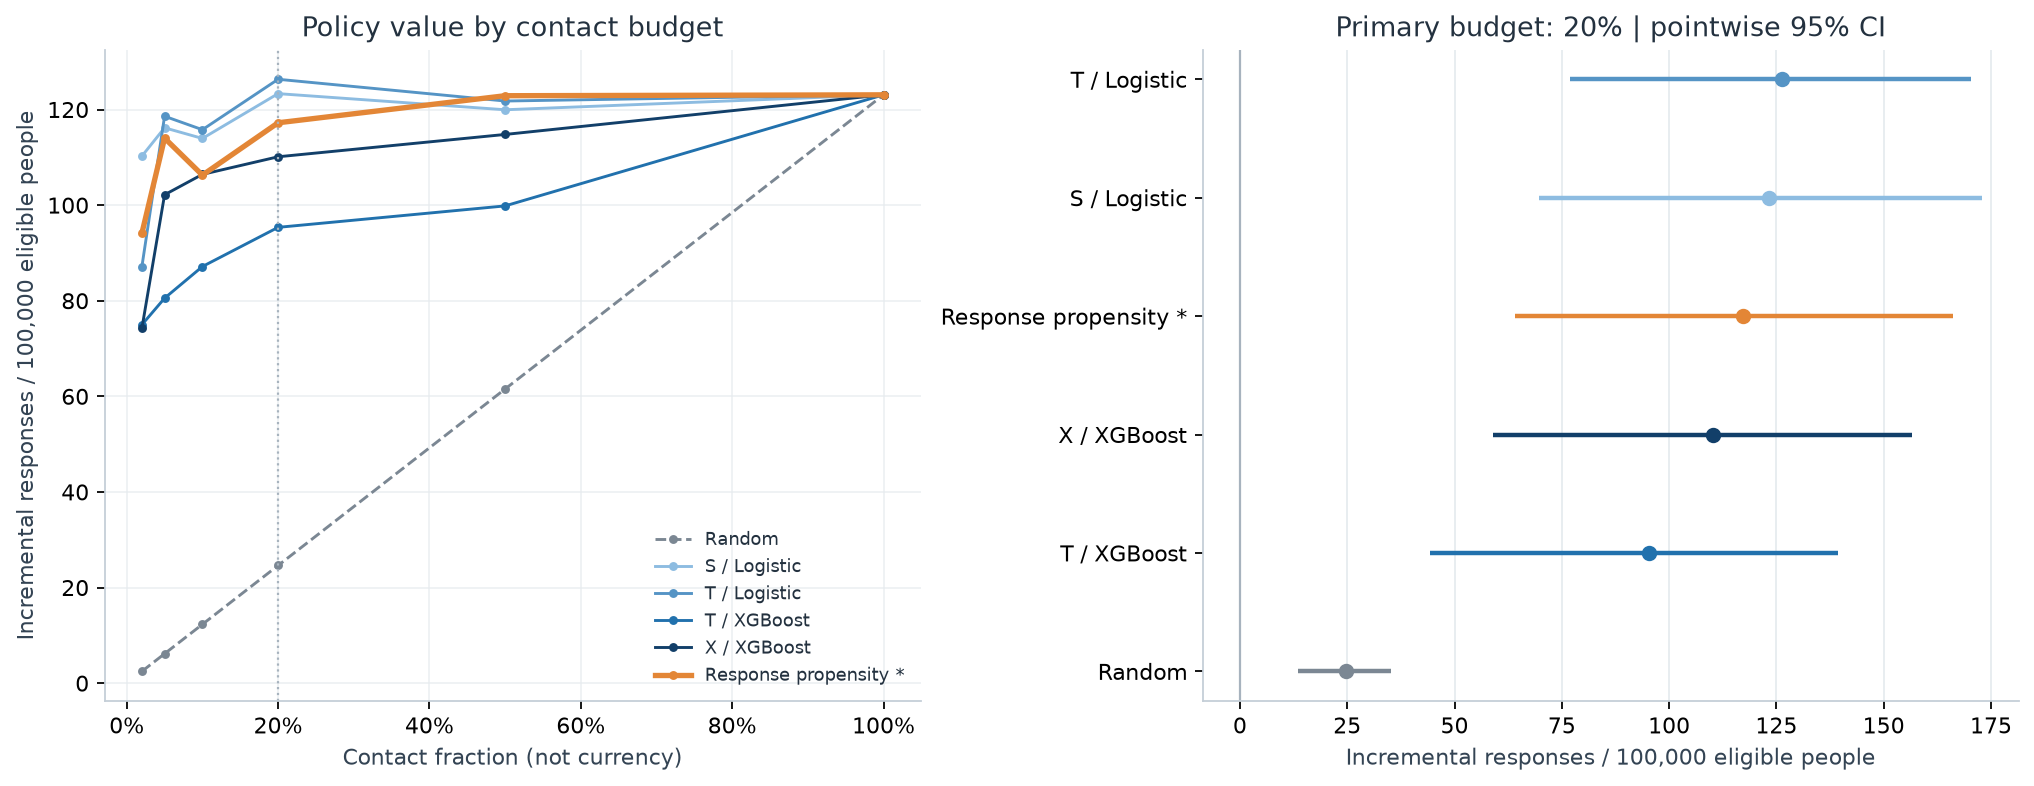

,policy,budget,incremental_per_100k,ci_low,ci_high
0,random,0.02,2.461499,1.357518,3.521645
1,random,0.05,6.153748,3.393796,8.804113
2,random,0.10,12.307497,6.787592,17.608226
3,random,0.20,24.614993,13.575185,35.216452
4,random,0.50,61.537483,33.937962,88.041131
5,random,1.00,123.074966,67.875924,176.082261
6,s_logistic,0.02,110.244853,76.295055,150.117459
7,s_logistic,0.05,116.180693,68.645158,162.329097
8,s_logistic,0.10,113.949668,59.293261,163.824110
9,s_logistic,0.20,123.324666,69.634569,172.808076


In [3]:
display(Image(filename=str(RUN/'figures/policy.png')))
display(policies[['policy','budget','incremental_per_100k','ci_low','ci_high']])

## 本轮结论如何读取

1. 以冻结政策在主预算的增量及成对差异 CI 为核心。
2. X-Learner 不保证比转化倾向策略好。若差异 CI 覆盖 0，应写“证据不足”，不要写“没有差异”或强行得出 uplift 胜出。
3. conversion 稀疏、control 更少，复杂模型可能不稳定；100 万开发样本的结果不等同全量建模最终结论。
4. 公布的预算表要求恰好选择 k 人；若业务改为“最多 k 人”，对 CATE 策略可增加只选预测正效应用户的规则，并在验证集确定，不能看测试结果临时加规则。
5. 下一阶段建议：多随机种子与特征分组敏感性分析已完成，见 notebook 06。扩样可作为后续预定检验；真实上线需独立 A/B 和真实成本数据。500 万/全量训练与线上实验尚未执行。

In [4]:
row=main[main.policy==selection['selected_policy']].iloc[0]
print(f"冻结政策 {row.policy}：每十万待选用户增量 {row.incremental_per_100k:.1f}，95% CI [{row.ci_low:.1f}, {row.ci_high:.1f}]")
print(f"相对 random 差值 {row.vs_random_per_100k:.1f}，成对95% CI [{row.vs_random_ci_low:.1f}, {row.vs_random_ci_high:.1f}]")
print('完整报告:', (RUN/'report.html').relative_to(ROOT))

冻结政策 propensity：每十万待选用户增量 117.2，95% CI [64.1, 166.2]
相对 random 差值 92.6，成对95% CI [50.0, 132.2]
完整报告: reports/published/conversion_1000000_seed42/report.html


## 学习笔记与版本

理论笔记中的标准误、MDE、C2ST 和版本比例已修正，见相应章节。本页展示历史冻结实验；新的 v2 指标和开发稳定性见 notebook 05/06。